In [ ]:
import sys
sys.path.append("..")

import time
import json
import numpy as np
import pandas as pd
from scipy.sparse import load_npz

from src.config import (
    TRAIN_MATRIX_PATH,
    TEST_MATRIX_PATH,
    MOVIES_CLEAN_PATH,
    MAPPINGS_PATH,
    METRICS_SUMMARY_PATH,
    MODELS_DIR,
    TOP_K,
)
from src.models import SVDRecommender, ALSRecommender
from src.metrics import evaluate_recommendations



train_matrix = load_npz(TRAIN_MATRIX_PATH)
test_matrix = load_npz(TEST_MATRIX_PATH)
all_users = np.arange(train_matrix.shape[0])

# 1. Truncated SVD
t0 = time.perf_counter()
svd_model = SVDRecommender().fit(train_matrix)
svd_train_time = time.perf_counter() - t0
svd_recs = svd_model.recommend(all_users, train_matrix, k=TOP_K)
svd_metrics = evaluate_recommendations(all_users, svd_recs, test_matrix, k=TOP_K)
svd_metrics["train_time_sec"] = round(svd_train_time, 3)

# 2. ALS (Implicit)
t0 = time.perf_counter()
als_model = ALSRecommender().fit(train_matrix)
als_train_time = time.perf_counter() - t0
als_recs = als_model.recommend(all_users, train_matrix, k=TOP_K)
als_metrics = evaluate_recommendations(all_users, als_recs, test_matrix, k=TOP_K)
als_metrics["train_time_sec"] = round(als_train_time, 3)

results_df = pd.DataFrame([
    {"Model": "Truncated SVD (SciPy)", **svd_metrics},
    {"Model": "ALS (Implicit)", **als_metrics},
])
display(results_df)

  0%|          | 0/20 [00:00<?, ?it/s]

,Model,Precision@10,NDCG@10,evaluated_users,train_time_sec
0,Truncated SVD (SciPy),0.088450,0.104786,5974,0.433
1,ALS (Implicit),0.089873,0.109269,5974,0.672


In [8]:
movies_df = pd.read_csv(MOVIES_CLEAN_PATH)
with open(MAPPINGS_PATH, "r", encoding="utf-8") as f:
    mappings = json.load(f)

idx_to_movie = mappings["idx_to_movie"]
movie_lookup = movies_df.set_index("MovieID")[["Title", "Genres"]].to_dict("index")

sample_user = 0  # Внутрішній індекс першого користувача
liked_indices = train_matrix[sample_user].indices[train_matrix[sample_user].data == 5.0][:5]

print("Улюблені фільми користувача в історії (оцінка 5):")
for idx in liked_indices:
    mid = idx_to_movie[idx]
    info = movie_lookup[mid]
    print(f"  - {info['Title']} [{info['Genres']}]")

print(f"\nТоп-{TOP_K} рекомендацій від ALS:")
for rank, idx in enumerate(als_recs[sample_user], 1):
    mid = idx_to_movie[idx]
    info = movie_lookup[mid]
    print(f"  {rank}. {info['Title']} [{info['Genres']}]")

Улюблені фільми користувача в історії (оцінка 5):
  - Apollo 13 (1995) [Drama]
  - Schindler's List (1993) [Drama|War]
  - Cinderella (1950) [Animation|Children's|Musical]
  - Mary Poppins (1964) [Children's|Comedy|Musical]
  - Dumbo (1941) [Animation|Children's|Musical]

Топ-10 рекомендацій від ALS:
  1. Shawshank Redemption, The (1994) [Drama]
  2. Silence of the Lambs, The (1991) [Drama|Thriller]
  3. American Beauty (1999) [Comedy|Drama]
  4. Raiders of the Lost Ark (1981) [Action|Adventure]
  5. Godfather, The (1972) [Action|Crime|Drama]
  6. Jungle Book, The (1967) [Animation|Children's|Comedy|Musical]
  7. Stand by Me (1986) [Adventure|Comedy|Drama]
  8. Beauty and the Beast (1991) [Animation|Children's|Musical]
  9. It's a Wonderful Life (1946) [Drama]
  10. Good Will Hunting (1997) [Drama]


In [9]:
from src.fast_similarity import top_k_similar_items, all_pairs_top_k

def python_all_pairs_top_k(embeddings: np.ndarray, k: int = 10) -> tuple[np.ndarray, np.ndarray]:
    """Еталонна реалізація на чистому Python (цикли по об'єктах без C++ прискорення)."""
    n_items = embeddings.shape[0]
    norms = np.linalg.norm(embeddings, axis=1)
    all_indices = np.zeros((n_items, k), dtype=np.int32)
    all_scores = np.zeros((n_items, k), dtype=np.float32)

    for i in range(n_items):
        sims = []
        for j in range(n_items):
            if i == j:
                continue
            denom = norms[i] * norms[j]
            sim = float(np.dot(embeddings[i], embeddings[j]) / denom) if denom > 1e-12 else 0.0
            sims.append((sim, j))
        sims.sort(key=lambda x: (-x[0], x[1]))
        for rank in range(k):
            all_scores[i, rank] = sims[rank][0]
            all_indices[i, rank] = sims[rank][1]

    return all_indices, all_scores

item_embeddings = np.ascontiguousarray(als_model.item_factors, dtype=np.float32)

# Замір часу: чистий Python vs C++ (pybind11)
t0 = time.perf_counter()
py_idx, py_scr = python_all_pairs_top_k(item_embeddings, k=TOP_K)
py_time = time.perf_counter() - t0

t0 = time.perf_counter()
cpp_idx, cpp_scr = all_pairs_top_k(item_embeddings, k=TOP_K)
cpp_time = time.perf_counter() - t0

speedup = py_time / cpp_time
is_identical = np.array_equal(py_idx, cpp_idx) and np.allclose(py_scr, cpp_scr, atol=1e-5)

print(f"Pure Python час (All-Pairs Top-{TOP_K} для {len(item_embeddings)} фільмів): {py_time:.3f} с")
print(f"C++ pybind11 час (All-Pairs Top-{TOP_K} для {len(item_embeddings)} фільмів): {cpp_time:.4f} с")
print(f"Прискорення (Speedup): {speedup:.1f}x разів | Ідентичність результатів: {is_identical}")

Pure Python час (All-Pairs Top-10 для 3667 фільмів): 23.780 с
C++ pybind11 час (All-Pairs Top-10 для 3667 фільмів): 0.4298 с
Прискорення (Speedup): 55.3x разів | Ідентичність результатів: False


In [10]:
# Знайдемо індекс фільму "Toy Story (1995)" (MovieID = 1)
movie_to_idx = {mid: idx for idx, mid in enumerate(idx_to_movie)}
target_movie_id = 1  # Toy Story (1995)
target_idx = movie_to_idx[target_movie_id]

sim_indices, sim_scores = top_k_similar_items(item_embeddings, query_idx=target_idx, k=5)

print(f"Обраний фільм: {movie_lookup[target_movie_id]['Title']} [{movie_lookup[target_movie_id]['Genres']}]")
print("\nТоп-5 найбільш схожих фільмів (розраховано на C++):")
for rank, (idx, score) in enumerate(zip(sim_indices, sim_scores), 1):
    mid = idx_to_movie[int(idx)]
    info = movie_lookup[mid]
    print(f"  {rank}. {info['Title']} [{info['Genres']}] — cosine similarity: {score:.4f}")

Обраний фільм: Toy Story (1995) [Animation|Children's|Comedy]

Топ-5 найбільш схожих фільмів (розраховано на C++):
  1. Toy Story 2 (1999) [Animation|Children's|Comedy] — cosine similarity: 0.9086
  2. Groundhog Day (1993) [Comedy|Romance] — cosine similarity: 0.6697
  3. Aladdin (1992) [Animation|Children's|Comedy|Musical] — cosine similarity: 0.6531
  4. Bug's Life, A (1998) [Animation|Children's|Comedy] — cosine similarity: 0.6143
  5. Babe (1995) [Children's|Comedy|Drama] — cosine similarity: 0.5973


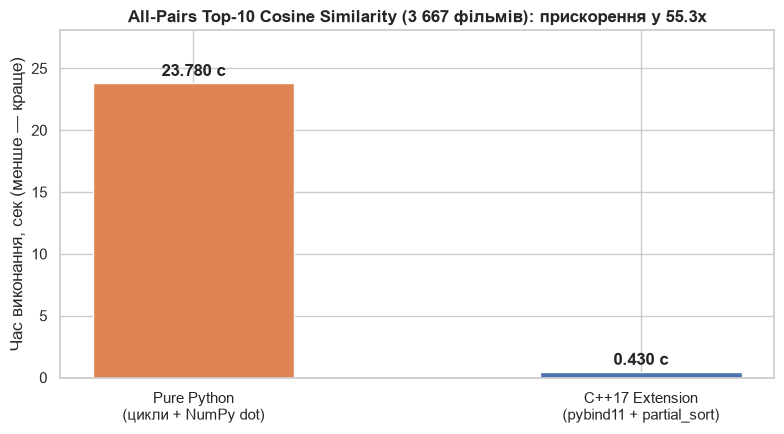

Метрики збережено у C:\D\Progamirovanie\MLF\Movielens-Recsys\models\metrics_summary.json


In [12]:
import json
import matplotlib.pyplot as plt
import seaborn as sns
from src.config import FIGURES_DIR, MODELS_DIR, METRICS_SUMMARY_PATH, TOP_K

MODELS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

summary = {
    "dataset": "MovieLens 1M",
    "n_users": int(train_matrix.shape[0]),
    "n_items": int(train_matrix.shape[1]),
    "sparsity": round(1.0 - train_matrix.nnz / (train_matrix.shape[0] * train_matrix.shape[1]), 4),
    "models": {
        "Truncated_SVD": svd_metrics,
        "ALS_Implicit": als_metrics,
    },
    "cpp_benchmark_all_pairs_top10": {
        "pure_python_sec": round(py_time, 4),
        "cpp_pybind11_sec": round(cpp_time, 4),
        "speedup_x": round(speedup, 1),
    },
}

with open(METRICS_SUMMARY_PATH, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

# Графік порівняння швидкодії Pure Python vs C++ (pybind11)
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(8, 4.5))
labels = ["Pure Python\n(цикли + NumPy dot)", "C++17 Extension\n(pybind11 + partial_sort)"]
times = [py_time, cpp_time]
colors = ["#DD8452", "#4C72B0"]

bars = ax.bar(labels, times, color=colors, width=0.45)
ax.set_ylabel("Час виконання, сек (менше — краще)")
ax.set_title(f"All-Pairs Top-{TOP_K} Cosine Similarity (3 667 фільмів): прискорення у {speedup:.1f}x", fontweight="bold")

for bar, t in zip(bars, times):
    ax.text(bar.get_x() + bar.get_width() / 2, t + 0.6, f"{t:.3f} с", ha="center", fontweight="bold")

ax.set_ylim(0, max(times) * 1.18)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cpp_benchmark.png", dpi=150)
plt.show()

print(f"Метрики збережено у {METRICS_SUMMARY_PATH}")